# 02 - Annotator Selection

**IT469 (King Saud University) - NER on Human-Written vs. LLM-Generated News**

## Purpose

This notebook builds the **annotator**: a Named Entity Recognition (NER) model that will later be used
to weakly-label the [LLM-generated News dataset](https://github.com/navid-aub/News-Dataset) (Ayoobi et al.,
2024), which has no entity annotations of its own. We fine-tune three candidate transformer encoders on the
human-annotated **CoNLL-2003** dataset [3], select the best configuration for each candidate on the
validation set, evaluate that single configuration once on the test set, and finally pick the candidate with
the highest validation F1 to serve as the silver-label annotator for the rest of the project
(see `03_silver_labeling.ipynb`).

## Dataset

**CoNLL-2003** [3] is a Reuters-derived news corpus annotated for four entity types: persons (PER),
organizations (ORG), locations (LOC), and miscellaneous (MISC). We use the official splits so our numbers
stay comparable with published work, and no cross-validation is used (fixed hold-out validation is standard
for this benchmark and keeps compute bounded):

| Split | Sentences |
|---|---|
| Train | 14,041 |
| Validation | 3,250 |
| Test | 3,453 |

Labels are IOB2-encoded with 9 classes: `O`, `B-PER`, `I-PER`, `B-ORG`, `I-ORG`, `B-LOC`, `I-LOC`, `B-MISC`,
`I-MISC` (ids 0-8, per the Hugging Face dataset card for `eriktks/conll2003`).

**Known label-noise caveat:** Wang et al. (2019, CrossWeigh) [4] found that roughly **5.38% of CoNLL-2003
test sentences contain annotation mistakes**. This caps the test F1 any model can realistically reach and is
a limitation of using CoNLL-2003 test performance as a proxy for annotator quality.

## Candidates

| Candidate | Hugging Face id | Why |
|---|---|---|
| `bert-base-cased` | `google-bert/bert-base-cased` | Standard reference point with widely published CoNLL-2003 results [1] |
| `roberta-base` | `FacebookAI/roberta-base` | Same parameter budget as BERT-base, but stronger pretraining [2] |
| `roberta-large` | `FacebookAI/roberta-large` | Largest capacity; annotation quality matters most at this stage, since every downstream model is trained on labels this model produces |

Three team members each run **this same notebook**, changing only `CANDIDATE` in the Configuration cell
(Section 1). Everything else — protocol, paths, code — is identical across the three runs.

## Full experimental protocol

| Setting | Value | Source / reason |
|---|---|---|
| Training data | CoNLL-2003 official train/validation/test splits (14,041 / 3,250 / 3,453 sentences) | Tjong Kim Sang & De Meulder (2003) [3]; keeps results comparable with published work |
| Cross-validation | None; fixed official splits, hold-out validation | Standard for CoNLL-2003; CV would break comparability and multiply compute |
| Granularity | Sentence level, no document context | The annotator is later applied to news sentence-by-sentence, so training matches deployment. BERT [1] used document context, so our scores are expected to be somewhat lower than BERT's reported 96.4 dev / 92.4 test F1 |
| Label scheme | 9 IOB2 labels: 0 `O`, 1 `B-PER`, 2 `I-PER`, 3 `B-ORG`, 4 `I-ORG`, 5 `B-LOC`, 6 `I-LOC`, 7 `B-MISC`, 8 `I-MISC` | HF dataset card for `eriktks/conll2003` |
| Subword labeling | Label on the first subword of each word; other subwords and special tokens get `-100` | Devlin et al. (2019) [1] |
| Output layer | Standard token classification head, no CRF | Devlin et al. (2019) [1] |
| Casing | Cased models only | Capitalization is a key NER cue; BERT used a cased model for NER [1] |
| Grid: learning rate | {1e-5, 2e-5, 3e-5} | Liu et al. (2019), RoBERTa §5.1 [2] |
| Grid: effective batch size | {16, 32} | Liu et al. (2019), RoBERTa §5.1 [2] |
| Max epochs | 10 | RoBERTa §5.1 [2]: "We finetune for 10 epochs and perform early stopping based on each task's evaluation metric on the dev set." |
| Early stopping | Validation entity-level micro F1, patience 3 | RoBERTa §5.1 [2] for early stopping on the dev metric; patience 3 is our practical choice (not specified by RoBERTa) to tolerate epoch-to-epoch fluctuation |
| Best epoch | Restore the epoch with the best validation F1 | Model selection on the dev set, as in BERT [1] and RoBERTa [2] |
| Warmup + schedule | Linear warmup over first 6% of steps, then linear decay to 0 | RoBERTa §5.1 [2] |
| Optimizer | AdamW | Loshchilov & Hutter (2019) [5]; Transformers [7] default |
| Weight decay | 0.1 | RoBERTa, Table 10 (GLUE) [2]; chosen so the whole protocol follows one source |
| Dropout | 0.1 (model default) | BERT [1] and RoBERTa [2] |
| Gradient clipping | max norm 1.0 | Transformers [7] default |
| Precision | fp16 mixed precision (CUDA GPU required) | Micikevicius et al. (2018) [6]; fits `roberta-large` on a T4 |
| Max sequence length | 256 subword tokens, truncation on, with an explicit check that no sentence is truncated | CoNLL sentences are short, but long ones can exceed 128 subwords; silent truncation would silently drop labels |
| Seed | 42, single fixed seed (Python, NumPy, PyTorch, Transformers `set_seed`) | Team decision; note that GPU training is not fully deterministic even with a fixed seed |
| Evaluation | Entity-level precision/recall/micro-F1 (plus per-type F1, macro F1) via `seqeval` [9], default (conlleval-compatible) mode | Standard CoNLL evaluation |
| Selection | Within a candidate: config with highest **validation** micro F1. Across candidates: candidate with highest **validation** micro F1 | Test scores are never used for any decision |
| Test policy | Each candidate's single best configuration is evaluated on test **exactly once**, after its grid is complete. The test split is not touched anywhere else | All candidates' test scores are reported for completeness; the selected annotator's test F1 estimates label quality |

## What gets saved, and where

Everything lives under one shared Google Drive folder, `ROOT = /content/drive/MyDrive/IT469-NER-Project`
(added as a Drive shortcut by every teammate, so the path is identical for all three). Each teammate writes
only inside their own candidate's (`{TAG}`) subfolders, so the three parallel runs never collide:

```
ROOT/
├── data/raw/conll2003/                                  # dataset cache (downloaded once, shared)
├── checkpoints/annotator/{TAG}/runs/{config}/           # temporary training checkpoints (deleted after each config)
├── checkpoints/annotator/{TAG}/best/                    # best model + tokenizer found so far
├── results/annotator/conll2003_stats.json               # dataset statistics (shared)
├── results/annotator/{TAG}/configs/{config}.json        # one result file per finished grid config
├── results/annotator/{TAG}/configs/{config}_history.csv # per-epoch train/val metrics
├── results/annotator/{TAG}/grid_summary.csv
├── results/annotator/{TAG}/best_config.json
├── results/annotator/{TAG}/val_predictions.jsonl
├── results/annotator/{TAG}/test.json                    # written once
├── results/annotator/{TAG}/test_predictions.jsonl
├── results/annotator/{TAG}/learning_curves.png
├── results/annotator/{TAG}/environment.json
├── results/annotator/{TAG}/run_log.txt
├── results/annotator/selected_annotator.json            # written by the comparison section once all 3 candidates are done
└── checkpoints/_smoke/, results/_smoke/                 # smoke-test outputs only, never mixed with real results
```

## Prerequisites

1. **GPU runtime.** Runtime > Change runtime type > T4 GPU. The notebook stops with a clear error if no CUDA
   GPU is visible.
2. **Drive shortcut.** You must have added a shortcut to the shared `IT469-NER-Project` folder in
   "My Drive" (Drive > Shared with me > find the folder > ⋮ > Organize > Add shortcut > My Drive). If
   `ROOT` does not exist after mounting, the notebook stops and tells you to do this.
3. **Free Drive space.** `roberta-large` needs roughly **9 GB free** during training, because the
   best-so-far model and the latest checkpoint (which also stores optimizer state) are both kept on disk at
   the same time.

## How to run

1. Edit **only** the Configuration cell (Section 1): set `CANDIDATE` to your assigned candidate. Leave
   `SMOKE_TEST = True` for your first run.
2. Runtime > Run all. The smoke test trains one tiny configuration for one epoch on a few hundred sentences
   and reports timing estimates, without touching any real result file.
3. Once the smoke test prints "Smoke test passed", set `SMOKE_TEST = False` and Runtime > Run all again. This
   runs the full 6-configuration grid search, picks the best configuration, and (once all 6 configs are done)
   evaluates it once on the test set.
4. If Colab disconnects midway, just Runtime > Run all again — every expensive step either skips (dataset
   download, finished grid configs, test evaluation) or resumes (an interrupted training run), so no work is
   repeated.
5. Section 10 (candidate comparison) only writes `selected_annotator.json` once all three teammates' results
   are visible in the shared Drive folder.

## References

In-text citations `[1]`-`[9]` point to the numbered list in Section 12 at the end of this notebook.


## 1. Configuration

This is the **only** cell you should edit. Each teammate changes `CANDIDATE` and nothing else.


In [27]:
# Configuration: candidate choice, smoke-test switch, and every protocol constant.

CANDIDATE = "bert-base-cased"   # one of: "bert-base-cased", "roberta-base", "roberta-large"
SMOKE_TEST = False                # True = fast pipeline check only; set False to run the real grid search

# --- fixed protocol constants (do not change; see Section 0 for sources) ---
CANDIDATE_TO_MODEL_ID = {
    "bert-base-cased": "google-bert/bert-base-cased",
    "roberta-base": "FacebookAI/roberta-base",
    "roberta-large": "FacebookAI/roberta-large",
}
assert CANDIDATE in CANDIDATE_TO_MODEL_ID, (
    f"CANDIDATE must be one of {list(CANDIDATE_TO_MODEL_ID)}, got {CANDIDATE!r}"
)
MODEL_ID = CANDIDATE_TO_MODEL_ID[CANDIDATE]
IS_ROBERTA = "roberta" in CANDIDATE  # RoBERTa's tokenizer needs add_prefix_space=True with pre-split tokens

LABEL_NAMES = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]
ID2LABEL = {i: name for i, name in enumerate(LABEL_NAMES)}
LABEL2ID = {name: i for i, name in enumerate(LABEL_NAMES)}

EXPECTED_SPLIT_SIZES = {"train": 14041, "validation": 3250, "test": 3453}

LEARNING_RATES = [1e-5, 2e-5, 3e-5]       # RoBERTa paper, Sec 5.1
BATCH_SIZES = [16, 32]                     # effective (post grad-accum) batch size, RoBERTa paper, Sec 5.1
MAX_EPOCHS = 10                            # RoBERTa paper, Sec 5.1
EARLY_STOPPING_PATIENCE = 3                # practical choice, not specified by RoBERTa
WEIGHT_DECAY = 0.1                         # RoBERTa paper, Table 10
WARMUP_FRACTION = 0.06                     # RoBERTa paper, Sec 5.1
MAX_SEQ_LENGTH = 256
SEED = 42
MAX_PER_DEVICE_BATCH = 16                  # cap to avoid OOM on roberta-large; grad accumulation covers bs=32

print("Active configuration")
print("---------------------")
print(f"CANDIDATE            : {CANDIDATE}")
print(f"MODEL_ID              : {MODEL_ID}")
print(f"IS_ROBERTA             : {IS_ROBERTA}")
print(f"SMOKE_TEST            : {SMOKE_TEST}")
print(f"LEARNING_RATES        : {LEARNING_RATES}")
print(f"BATCH_SIZES (eff.)    : {BATCH_SIZES}")
print(f"MAX_EPOCHS            : {MAX_EPOCHS}")
print(f"EARLY_STOPPING_PATIENCE: {EARLY_STOPPING_PATIENCE}")
print(f"WEIGHT_DECAY          : {WEIGHT_DECAY}")
print(f"WARMUP_FRACTION       : {WARMUP_FRACTION}")
print(f"MAX_SEQ_LENGTH        : {MAX_SEQ_LENGTH}")
print(f"SEED                  : {SEED}")
print(f"MAX_PER_DEVICE_BATCH  : {MAX_PER_DEVICE_BATCH}")
print(f"Number of grid configs: {len(LEARNING_RATES) * len(BATCH_SIZES)}")


Active configuration
---------------------
CANDIDATE            : bert-base-cased
MODEL_ID              : google-bert/bert-base-cased
IS_ROBERTA             : False
SMOKE_TEST            : False
LEARNING_RATES        : [1e-05, 2e-05, 3e-05]
BATCH_SIZES (eff.)    : [16, 32]
MAX_EPOCHS            : 10
EARLY_STOPPING_PATIENCE: 3
WEIGHT_DECAY          : 0.1
WARMUP_FRACTION       : 0.06
MAX_SEQ_LENGTH        : 256
SEED                  : 42
MAX_PER_DEVICE_BATCH  : 16
Number of grid configs: 6


## 2. Setup

Install anything missing, import libraries, verify the Transformers API we rely on, require a CUDA GPU, and fix every random seed.


In [28]:
!pip install -q -U pip setuptools wheel

In [29]:
# Setup: install only what Colab is missing. seqeval is never preinstalled; datasets/accelerate usually are,
# so we avoid reinstalling them (that can pull in versions that don't match Colab's preinstalled torch).
!pip install -q seqeval

import importlib
import subprocess
import sys

def _ensure_installed(import_name, pip_name=None):
    try:
        importlib.import_module(import_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or import_name])

_ensure_installed("datasets")
_ensure_installed("accelerate")


In [30]:
# Imports used throughout the notebook.
import gc
import importlib.metadata
import json
import logging
import math
import platform
import random
import shutil
import time
import traceback
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import datasets
import transformers
import accelerate
from datasets import load_dataset, load_from_disk, Dataset, DatasetDict
from huggingface_hub import list_repo_files, hf_hub_download
from sklearn.model_selection import ParameterGrid
from seqeval.metrics import precision_score, recall_score, f1_score, classification_report
from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    DataCollatorForTokenClassification,
    TrainingArguments,
    Trainer,
    TrainerCallback,
    EarlyStoppingCallback,
    set_seed,
)


In [31]:
# Require a current Transformers API: eval_strategy (not evaluation_strategy) and processing_class
# (not tokenizer=) were introduced in 4.46; older versions would silently use different defaults.
_tf_version_parts = tuple(int(p) for p in transformers.__version__.split(".")[:2])
assert _tf_version_parts >= (4, 46), (
    f"This notebook requires transformers >= 4.46 (found {transformers.__version__}). "
    "Restart the runtime after `pip install -U transformers` if Colab's preinstalled version is older."
)

# Require a CUDA GPU: fp16 training and the roberta-large memory budget both depend on it.
if not torch.cuda.is_available():
    raise RuntimeError(
        "No CUDA GPU detected. In Colab: Runtime > Change runtime type > T4 GPU, "
        "then Runtime > Run all again."
    )
GPU_NAME = torch.cuda.get_device_name(0)
print(f"GPU detected: {GPU_NAME}")

# Fix every source of randomness we control. GPU training is still not fully deterministic
# (non-deterministic cuDNN kernels), so exact bit-for-bit reproduction is not expected even so.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
set_seed(SEED)

ENV_INFO = {
    "date_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "transformers_version": transformers.__version__,
    "datasets_version": datasets.__version__,
    "accelerate_version": accelerate.__version__,
    "seqeval_version": importlib.metadata.version("seqeval"),
    "gpu_name": GPU_NAME,
    "candidate": CANDIDATE,
    "model_id": MODEL_ID,
    "smoke_test": SMOKE_TEST,
}
print(json.dumps(ENV_INFO, indent=2))


GPU detected: NVIDIA A100-SXM4-40GB
{
  "date_utc": "2026-10-15T09:44:05.236867+00:00",
  "python_version": "3.13.15",
  "torch_version": "2.11.0+cu130",
  "transformers_version": "5.18.0",
  "datasets_version": "4.8.5",
  "accelerate_version": "1.15.0",
  "seqeval_version": "1.2.2",
  "gpu_name": "NVIDIA A100-SXM4-40GB",
  "candidate": "bert-base-cased",
  "model_id": "google-bert/bert-base-cased",
  "smoke_test": false
}


## 3. Mount Drive and paths

Mount Google Drive, resolve every path from the single `ROOT` variable, create folders, and set up logging that survives disconnects.


In [32]:
# Mount Drive and locate the shared project folder.
from google.colab import drive
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/IT469-NER-Project")
if not ROOT.exists():
    raise RuntimeError(
        f"{ROOT} does not exist. Add the shared folder as a shortcut in your own My Drive: "
        "Google Drive > Shared with me > IT469-NER-Project > (right-click) Organize > "
        "Add shortcut > My Drive. Then re-run this cell."
    )
print(f"ROOT resolved: {ROOT}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ROOT resolved: /content/drive/MyDrive/IT469-NER-Project


In [33]:
# Resolve every other path from ROOT. Smoke-test runs are redirected to dedicated _smoke folders so they
# never touch real results, independent of which candidate is configured.
DATA_DIR = ROOT / "data" / "raw" / "conll2003"
STATS_JSON = ROOT / "results" / "annotator" / "conll2003_stats.json"           # shared across candidates
SELECTED_ANNOTATOR_JSON = ROOT / "results" / "annotator" / "selected_annotator.json"

if SMOKE_TEST:
    RESULTS_DIR = ROOT / "results" / "_smoke"
    CKPT_DIR = ROOT / "checkpoints" / "_smoke"
else:
    RESULTS_DIR = ROOT / "results" / "annotator" / CANDIDATE
    CKPT_DIR = ROOT / "checkpoints" / "annotator" / CANDIDATE

CONFIGS_DIR = RESULTS_DIR / "configs"
GRID_SUMMARY_CSV = RESULTS_DIR / "grid_summary.csv"
BEST_CONFIG_JSON = RESULTS_DIR / "best_config.json"
VAL_PREDICTIONS_JSONL = RESULTS_DIR / "val_predictions.jsonl"
TEST_JSON = RESULTS_DIR / "test.json"
TEST_PREDICTIONS_JSONL = RESULTS_DIR / "test_predictions.jsonl"
LEARNING_CURVES_PNG = RESULTS_DIR / "learning_curves.png"
ENVIRONMENT_JSON = RESULTS_DIR / "environment.json"
RUN_LOG_TXT = RESULTS_DIR / "run_log.txt"

RUNS_DIR = CKPT_DIR / "runs"
BEST_DIR = CKPT_DIR / "best"
BEST_TMP_DIR = CKPT_DIR / "best_tmp"

for d in [DATA_DIR.parent, STATS_JSON.parent, RESULTS_DIR, CONFIGS_DIR, CKPT_DIR, RUNS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"RESULTS_DIR: {RESULTS_DIR}")
print(f"CKPT_DIR   : {CKPT_DIR}")


RESULTS_DIR: /content/drive/MyDrive/IT469-NER-Project/results/annotator/bert-base-cased
CKPT_DIR   : /content/drive/MyDrive/IT469-NER-Project/checkpoints/annotator/bert-base-cased


In [34]:
# Logger that writes to run_log.txt (appended, so it survives disconnects) AND prints to the cell output.
logger = logging.getLogger(f"annotator_{CANDIDATE}_{'smoke' if SMOKE_TEST else 'full'}")
logger.setLevel(logging.INFO)
logger.handlers.clear()  # avoid duplicate handlers if this cell is re-run

_formatter = logging.Formatter("%(asctime)s [%(levelname)s] %(message)s")

_file_handler = logging.FileHandler(RUN_LOG_TXT, mode="a", encoding="utf-8")
_file_handler.setFormatter(_formatter)
logger.addHandler(_file_handler)

_stream_handler = logging.StreamHandler()
_stream_handler.setFormatter(_formatter)
logger.addHandler(_stream_handler)


def save_json(obj, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)


def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


save_json(ENV_INFO, ENVIRONMENT_JSON)
logger.info(f"Session started. candidate={CANDIDATE} smoke_test={SMOKE_TEST} root={ROOT}")
logger.info(f"Environment: {ENV_INFO}")


2026-10-15 09:44:14,989 [INFO] Session started. candidate=bert-base-cased smoke_test=False root=/content/drive/MyDrive/IT469-NER-Project
INFO:annotator_bert-base-cased_full:Session started. candidate=bert-base-cased smoke_test=False root=/content/drive/MyDrive/IT469-NER-Project
2026-10-15 09:44:14,991 [INFO] Environment: {'date_utc': '2026-10-15T09:44:05.236867+00:00', 'python_version': '3.13.15', 'torch_version': '2.11.0+cu130', 'transformers_version': '5.18.0', 'datasets_version': '4.8.5', 'accelerate_version': '1.15.0', 'seqeval_version': '1.2.2', 'gpu_name': 'NVIDIA A100-SXM4-40GB', 'candidate': 'bert-base-cased', 'model_id': 'google-bert/bert-base-cased', 'smoke_test': False}
INFO:annotator_bert-base-cased_full:Environment: {'date_utc': '2026-10-15T09:44:05.236867+00:00', 'python_version': '3.13.15', 'torch_version': '2.11.0+cu130', 'transformers_version': '5.18.0', 'datasets_version': '4.8.5', 'accelerate_version': '1.15.0', 'seqeval_version': '1.2.2', 'gpu_name': 'NVIDIA A100-SX

## 4. Load CoNLL-2003

Load the dataset (caching it to Drive the first time), verify split sizes and label set, compute dataset statistics, and keep only the columns we need.


In [35]:
# Load CoNLL-2003: use the Drive cache if a previous run already built it, otherwise download it.
if DATA_DIR.exists() and any(DATA_DIR.iterdir()):
    logger.info(f"Loading cached dataset from {DATA_DIR}")
    raw_dataset = load_from_disk(str(DATA_DIR))
else:
    logger.info("No cached dataset found. Downloading CoNLL-2003 ...")
    try:
        # The original eriktks/conll2003 repo uses a loading script that recent `datasets`
        # versions refuse to run; the auto-converted Parquet revision avoids that.
        raw_dataset = load_dataset("eriktks/conll2003", revision="refs/convert/parquet")
    except Exception as e:
        logger.warning(f"load_dataset with refs/convert/parquet failed ({e}); falling back to manual Parquet download")
        repo_id = "eriktks/conll2003"
        files = list_repo_files(repo_id, repo_type="dataset", revision="refs/convert/parquet")
        parquet_files = [f for f in files if f.endswith(".parquet")]

        split_to_files = {"train": [], "validation": [], "test": []}
        for f in parquet_files:
            for split in split_to_files:
                if f"/{split}/" in f or f.split("/")[-1].startswith(split):
                    split_to_files[split].append(f)

        split_datasets = {}
        for split, split_files in split_to_files.items():
            assert split_files, f"No parquet files found for split {split!r} among {parquet_files}"
            local_paths = [
                hf_hub_download(repo_id, f, repo_type="dataset", revision="refs/convert/parquet")
                for f in split_files
            ]
            split_datasets[split] = Dataset.from_parquet(local_paths)
        raw_dataset = DatasetDict(split_datasets)

    DATA_DIR.mkdir(parents=True, exist_ok=True)
    raw_dataset.save_to_disk(str(DATA_DIR))
    logger.info(f"Dataset cached to {DATA_DIR}")

print(raw_dataset)


2026-10-15 09:44:17,270 [INFO] Loading cached dataset from /content/drive/MyDrive/IT469-NER-Project/data/raw/conll2003
INFO:annotator_bert-base-cased_full:Loading cached dataset from /content/drive/MyDrive/IT469-NER-Project/data/raw/conll2003


DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})


In [36]:
# Verify split sizes and the label set before doing anything else with the data.
for split, expected_size in EXPECTED_SPLIT_SIZES.items():
    actual_size = len(raw_dataset[split])
    assert actual_size == expected_size, (
        f"Expected {expected_size} sentences in split {split!r}, found {actual_size}. "
        "The cached/downloaded dataset does not match the official CoNLL-2003 splits."
    )

ner_feature = raw_dataset["train"].features["ner_tags"]
if hasattr(ner_feature, "feature") and hasattr(ner_feature.feature, "names"):
    label_names_from_data = ner_feature.feature.names
else:
    label_names_from_data = LABEL_NAMES  # hard-coded fallback from Section 1

assert len(label_names_from_data) == 9, (
    f"Expected exactly 9 NER labels, found {len(label_names_from_data)}: {label_names_from_data}"
)
assert label_names_from_data == LABEL_NAMES, (
    f"Label order from the dataset {label_names_from_data} does not match the protocol order {LABEL_NAMES}"
)
logger.info(f"Split sizes OK: {EXPECTED_SPLIT_SIZES}. Label set OK: {LABEL_NAMES}")


2026-10-15 09:44:19,935 [INFO] Split sizes OK: {'train': 14041, 'validation': 3250, 'test': 3453}. Label set OK: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
INFO:annotator_bert-base-cased_full:Split sizes OK: {'train': 14041, 'validation': 3250, 'test': 3453}. Label set OK: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']


In [37]:
# Dataset statistics: sentence counts and entity-mention counts per type per split, via BIO span extraction.

def count_entity_spans(ner_tags, label_names):
    '''Count entity mentions by type using standard BIO span extraction (a mention starts at B-X).'''
    counts = {}
    for tag_id in ner_tags:
        tag = label_names[tag_id]
        if tag.startswith("B-"):
            ent_type = tag[2:]
            counts[ent_type] = counts.get(ent_type, 0) + 1
    return counts


if STATS_JSON.exists():
    logger.info(f"Dataset stats already computed, loading {STATS_JSON}")
    conll_stats = load_json(STATS_JSON)
else:
    conll_stats = {}
    for split in ["train", "validation", "test"]:
        split_data = raw_dataset[split]
        entity_counts = {}
        for example in split_data:
            for ent_type, cnt in count_entity_spans(example["ner_tags"], LABEL_NAMES).items():
                entity_counts[ent_type] = entity_counts.get(ent_type, 0) + cnt
        conll_stats[split] = {
            "num_sentences": len(split_data),
            "num_entities_by_type": entity_counts,
            "num_entities_total": sum(entity_counts.values()),
        }
    save_json(conll_stats, STATS_JSON)
    logger.info(f"Dataset stats saved to {STATS_JSON}")

stats_rows = []
for split, s in conll_stats.items():
    row = {"split": split, "sentences": s["num_sentences"], "total_entities": s["num_entities_total"]}
    row.update({f"entities_{k}": v for k, v in s["num_entities_by_type"].items()})
    stats_rows.append(row)
display(pd.DataFrame(stats_rows).set_index("split"))


2026-10-15 09:44:22,023 [INFO] Dataset stats already computed, loading /content/drive/MyDrive/IT469-NER-Project/results/annotator/conll2003_stats.json
INFO:annotator_bert-base-cased_full:Dataset stats already computed, loading /content/drive/MyDrive/IT469-NER-Project/results/annotator/conll2003_stats.json


,sentences,total_entities,entities_ORG,entities_MISC,entities_PER,entities_LOC
split,,,,,,
train,14041,23499,6321,3438,6600,7140
validation,3250,5942,1341,922,1842,1837
test,3453,5648,1661,702,1617,1668


In [38]:
# Keep only the columns the rest of the notebook needs.
columns_to_keep = ["tokens", "ner_tags"]
raw_dataset = DatasetDict({
    split: ds.remove_columns([c for c in ds.column_names if c not in columns_to_keep])
    for split, ds in raw_dataset.items()
})

train_raw = raw_dataset["train"]
validation_raw = raw_dataset["validation"]
test_raw = raw_dataset["test"]  # not touched again until Section 9

if SMOKE_TEST:
    # Shrink train/validation only, so the pipeline logic is exercised end to end without full-scale compute.
    # Stats above were computed on the FULL dataset; this subsampling happens only after that.
    train_raw = train_raw.select(range(min(200, len(train_raw))))
    validation_raw = validation_raw.select(range(min(100, len(validation_raw))))
    logger.info(f"SMOKE_TEST: using {len(train_raw)} train / {len(validation_raw)} validation sentences")

print(f"train={len(train_raw)}  validation={len(validation_raw)}  test={len(test_raw)}")


train=14041  validation=3250  test=3453


## 5. Tokenization and label alignment

Tokenize with the candidate's tokenizer, align each word's label onto its first subword only (`-100` elsewhere), and verify nothing gets silently truncated. Only train/validation are tokenized here — test stays untouched until Section 9.


In [39]:
# RoBERTa's BPE tokenizer needs add_prefix_space=True to tokenize pre-split word lists correctly.
if IS_ROBERTA:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, add_prefix_space=True)
else:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
print(f"Loaded tokenizer: {tokenizer.__class__.__name__} (add_prefix_space={IS_ROBERTA})")


Loaded tokenizer: BertTokenizer (add_prefix_space=False)


In [40]:
# Tokenize and align labels: each word's label goes on its first subword; other subwords and
# special tokens ([CLS]/[SEP]/<s>/</s>/padding) get -100 so the loss ignores them.

def tokenize_and_align_labels(examples):
    tokenized = tokenizer(
        examples["tokens"],
        is_split_into_words=True,
        truncation=True,
        max_length=MAX_SEQ_LENGTH,
    )
    all_labels = []
    for i, tags in enumerate(examples["ner_tags"]):
        word_ids = tokenized.word_ids(batch_index=i)
        labels, prev_word_id = [], None
        for word_id in word_ids:
            if word_id is None:
                labels.append(-100)
            elif word_id != prev_word_id:
                labels.append(tags[word_id])
            else:
                labels.append(-100)
            prev_word_id = word_id
        all_labels.append(labels)
    tokenized["labels"] = all_labels
    return tokenized


train_tokenized = train_raw.map(tokenize_and_align_labels, batched=True, remove_columns=train_raw.column_names)
validation_tokenized = validation_raw.map(
    tokenize_and_align_labels, batched=True, remove_columns=validation_raw.column_names
)
print(f"Tokenized train={len(train_tokenized)}  validation={len(validation_tokenized)}")


Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Tokenized train=14041  validation=3250


In [41]:
# Visually confirm the alignment on one example: word | subword tokens | label.
example = train_raw[0]
encoded = tokenizer(example["tokens"], is_split_into_words=True, truncation=True, max_length=MAX_SEQ_LENGTH)
word_ids = encoded.word_ids()
subword_tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"])

rows = []
seen_words = set()
for subword, word_id in zip(subword_tokens, word_ids):
    if word_id is None:
        continue
    label_str = LABEL_NAMES[example["ner_tags"][word_id]] if word_id not in seen_words else "(same word)"
    rows.append({"word": example["tokens"][word_id], "subword": subword, "label": label_str})
    seen_words.add(word_id)
display(pd.DataFrame(rows))


,word,subword,label
0,EU,EU,B-ORG
1,rejects,rejects,O
2,German,German,B-MISC
3,call,call,O
4,to,to,O
5,boycott,boycott,O
6,British,British,B-MISC
7,lamb,la,O
8,lamb,##mb,(same word)
9,.,.,O


In [42]:
# Truncation check: no sentence should lose words to the 256-subword cap, since that would silently
# drop labels. We count, per sentence, labeled positions (non -100) against the original word count.

def find_truncated_sentences(tokenized_dataset, raw_dataset_split):
    truncated_indices = []
    for i in range(len(tokenized_dataset)):
        num_labeled = sum(1 for l in tokenized_dataset[i]["labels"] if l != -100)
        num_words = len(raw_dataset_split[i]["tokens"])
        if num_labeled < num_words:
            truncated_indices.append(i)
    return truncated_indices


truncated_train = find_truncated_sentences(train_tokenized, train_raw)
truncated_val = find_truncated_sentences(validation_tokenized, validation_raw)

if truncated_train or truncated_val:
    logger.warning(
        f"Truncation detected at max_length={MAX_SEQ_LENGTH}. "
        f"train indices (first 20): {truncated_train[:20]}, validation indices (first 20): {truncated_val[:20]}"
    )
assert not truncated_train and not truncated_val, (
    f"{len(truncated_train)} train and {len(truncated_val)} validation sentences were truncated at "
    f"max_length={MAX_SEQ_LENGTH} and would silently lose labels. See the logged warning for indices."
)
logger.info(f"Truncation check OK: no sentence exceeds {MAX_SEQ_LENGTH} subword tokens")


2026-10-15 09:44:45,331 [INFO] Truncation check OK: no sentence exceeds 256 subword tokens
INFO:annotator_bert-base-cased_full:Truncation check OK: no sentence exceeds 256 subword tokens


In [43]:
# Pads inputs AND labels together to the longest sequence in each batch (label padding value = -100).
data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer)


## 6. Metrics

Entity-level precision/recall/F1 via `seqeval`, in the default (conlleval-compatible) scheme [9].


In [44]:
# compute_metrics for the Trainer: converts ids back to label strings, drops -100 positions,
# and returns entity-level micro precision/recall/F1 plus token accuracy.

def _predictions_to_label_strings(predictions, labels):
    pred_ids = np.argmax(predictions, axis=2)
    true_label_strs, pred_label_strs = [], []
    for pred_seq, label_seq in zip(pred_ids, labels):
        true_seq, pred_seq_strs = [], []
        for p, l in zip(pred_seq, label_seq):
            if l == -100:
                continue
            true_seq.append(LABEL_NAMES[l])
            pred_seq_strs.append(LABEL_NAMES[p])
        true_label_strs.append(true_seq)
        pred_label_strs.append(pred_seq_strs)
    return true_label_strs, pred_label_strs


def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    true_label_strs, pred_label_strs = _predictions_to_label_strings(predictions, labels)
    n_correct = sum(t == p for seq_t, seq_p in zip(true_label_strs, pred_label_strs) for t, p in zip(seq_t, seq_p))
    n_total = sum(len(seq) for seq in true_label_strs)
    return {
        "precision": precision_score(true_label_strs, pred_label_strs),
        "recall": recall_score(true_label_strs, pred_label_strs),
        "f1": f1_score(true_label_strs, pred_label_strs),
        "accuracy": n_correct / n_total if n_total else 0.0,
    }


def full_seqeval_report(predictions, labels):
    '''Per-type + macro/micro seqeval classification_report, for saving (not for Trainer's eval loop).'''
    true_label_strs, pred_label_strs = _predictions_to_label_strings(predictions, labels)
    report = classification_report(true_label_strs, pred_label_strs, output_dict=True)
    return report, true_label_strs, pred_label_strs


## 7. Grid search (resumable)

Train all 6 (lr, batch size) configurations. Finished configs are skipped; an interrupted config resumes from its last epoch checkpoint. Every failure (e.g. out-of-memory) is caught so the rest of the grid still runs.


In [45]:
# Callback: logs validation F1 prominently after every epoch, and warns if epoch-1 F1 suggests
# fine-tuning collapsed (observed occasionally with large models at the higher end of the LR grid).

class EpochF1Logger(TrainerCallback):
    def __init__(self, logger_, low_f1_threshold=0.10):
        self.logger_ = logger_
        self.low_f1_threshold = low_f1_threshold

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        if not metrics or "eval_f1" not in metrics:
            return
        epoch = metrics.get("epoch", state.epoch) or 0.0
        f1, precision, recall = metrics["eval_f1"], metrics.get("eval_precision"), metrics.get("eval_recall")
        self.logger_.info(f"  epoch {round(epoch)}: val precision={precision:.4f} recall={recall:.4f} F1={f1:.4f}")
        if round(epoch) == 1 and f1 < self.low_f1_threshold:
            self.logger_.warning(
                f"Validation F1 after epoch 1 is only {f1:.4f} (< {self.low_f1_threshold}). "
                "Fine-tuning may have collapsed (known to happen for large models at some learning "
                "rates) -- if this config's final F1 is also poor, consider a lower learning rate."
            )


In [46]:
# Helpers used by the grid-search loop below.

def compute_warmup_steps(num_train_examples, effective_batch_size, num_epochs, warmup_fraction):
    # Warmup is sized against the full 10-epoch schedule (RoBERTa Sec 5.1), independent of how many
    # epochs this particular run actually trains for (early stopping may cut it short).
    steps_per_epoch = math.ceil(num_train_examples / effective_batch_size)
    total_steps = steps_per_epoch * num_epochs
    return math.ceil(warmup_fraction * total_steps), total_steps


def save_training_history(log_history, out_csv_path):
    # Merge the per-epoch train-loss log entries with the per-epoch eval entries into one row per epoch.
    rows_by_epoch = {}
    for entry in log_history:
        if "epoch" not in entry:
            continue
        epoch = int(round(entry["epoch"]))
        row = rows_by_epoch.setdefault(epoch, {"epoch": epoch})
        if "loss" in entry and "eval_loss" not in entry:
            row["train_loss"] = entry["loss"]
        if "eval_loss" in entry:
            row["eval_loss"] = entry["eval_loss"]
            row["eval_precision"] = entry.get("eval_precision")
            row["eval_recall"] = entry.get("eval_recall")
            row["eval_f1"] = entry.get("eval_f1")
    history_df = pd.DataFrame(sorted(rows_by_epoch.values(), key=lambda r: r["epoch"]))
    out_csv_path.parent.mkdir(parents=True, exist_ok=True)
    history_df.to_csv(out_csv_path, index=False)
    return history_df


def predict_with_report(trainer_, tokenized_split, raw_split):
    output = trainer_.predict(tokenized_split)
    report, true_label_strs, pred_label_strs = full_seqeval_report(output.predictions, output.label_ids)
    records = [
        {"tokens": raw_split[i]["tokens"], "gold": gold, "predicted": pred}
        for i, (gold, pred) in enumerate(zip(true_label_strs, pred_label_strs))
    ]
    return report, records


def write_jsonl(records, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record) + "\n")


def update_best_if_better(config_name, val_f1, model_, tokenizer_, val_records):
    # Keeps best/ always a COMPLETE model: write to a tmp dir first, then atomically swap it in.
    current_best = load_json(BEST_CONFIG_JSON) if BEST_CONFIG_JSON.exists() else None
    if current_best is not None and val_f1 <= current_best["val_f1"]:
        logger.info(f"{config_name}: val F1 {val_f1:.4f} does not beat current best {current_best['val_f1']:.4f}")
        return False

    previous = f"{current_best['val_f1']:.4f}" if current_best else "none"
    logger.info(f"{config_name}: new best val F1 {val_f1:.4f} (previous best: {previous})")

    if BEST_TMP_DIR.exists():
        shutil.rmtree(BEST_TMP_DIR)
    BEST_TMP_DIR.mkdir(parents=True, exist_ok=True)
    model_.save_pretrained(BEST_TMP_DIR)
    tokenizer_.save_pretrained(BEST_TMP_DIR)
    if BEST_DIR.exists():
        shutil.rmtree(BEST_DIR)
    BEST_TMP_DIR.rename(BEST_DIR)

    write_jsonl(val_records, VAL_PREDICTIONS_JSONL)
    save_json(
        {
            "config": config_name,
            "val_f1": val_f1,
            "candidate": CANDIDATE,
            "model_id": MODEL_ID,
            "updated_at": datetime.now(timezone.utc).isoformat(),
        },
        BEST_CONFIG_JSON,
    )
    return True


In [47]:
# Build the grid: 6 configs normally, or 1 tiny config under SMOKE_TEST.
if SMOKE_TEST:
    grid_configs = [{"lr": 2e-5, "bs": 16}]
    GRID_EPOCHS = 1
else:
    grid_configs = list(ParameterGrid({"lr": LEARNING_RATES, "bs": BATCH_SIZES}))
    GRID_EPOCHS = MAX_EPOCHS

failures = []
smoke_timings = []  # (config_name, elapsed_seconds, num_steps) -- only populated under SMOKE_TEST
grid_config_names = [f"lr{c['lr']:.0e}_bs{c['bs']}" for c in grid_configs]
print(f"Grid configs to run: {grid_config_names}")


Grid configs to run: ['lr1e-05_bs16', 'lr2e-05_bs16', 'lr3e-05_bs16', 'lr1e-05_bs32', 'lr2e-05_bs32', 'lr3e-05_bs32']


In [48]:
# Main grid-search loop. Resumable: finished configs are skipped, interrupted ones resume.
for cfg in grid_configs:
    lr, bs = cfg["lr"], cfg["bs"]
    config_name = f"lr{lr:.0e}_bs{bs}"
    config_json_path = CONFIGS_DIR / f"{config_name}.json"
    run_dir = RUNS_DIR / config_name

    if config_json_path.exists():
        logger.info(f"{config_name}: skipped (already done)")
        continue

    logger.info(f"{config_name}: starting (lr={lr}, effective_bs={bs}, max_epochs={GRID_EPOCHS})")
    model, trainer = None, None
    try:
        per_device_bs = min(bs, MAX_PER_DEVICE_BATCH)
        grad_accum = bs // per_device_bs
        warmup_steps, _ = compute_warmup_steps(len(train_tokenized), bs, MAX_EPOCHS, WARMUP_FRACTION)

        model = AutoModelForTokenClassification.from_pretrained(
            MODEL_ID, num_labels=len(LABEL_NAMES), id2label=ID2LABEL, label2id=LABEL2ID
        )

        training_args = TrainingArguments(
            output_dir=str(run_dir),
            eval_strategy="epoch",
            save_strategy="epoch",
            logging_strategy="epoch",
            load_best_model_at_end=True,
            metric_for_best_model="f1",
            greater_is_better=True,
            save_total_limit=1,
            num_train_epochs=GRID_EPOCHS,
            learning_rate=lr,
            per_device_train_batch_size=per_device_bs,
            per_device_eval_batch_size=32,
            gradient_accumulation_steps=grad_accum,
            weight_decay=WEIGHT_DECAY,
            warmup_steps=warmup_steps,
            lr_scheduler_type="linear",
            max_grad_norm=1.0,
            fp16=True,
            seed=SEED,
            report_to="none",
        )

        trainer = Trainer(
            model=model,
            args=training_args,
            train_dataset=train_tokenized,
            eval_dataset=validation_tokenized,
            data_collator=data_collator,
            processing_class=tokenizer,
            compute_metrics=compute_metrics,
            callbacks=[
                EarlyStoppingCallback(early_stopping_patience=EARLY_STOPPING_PATIENCE),
                EpochF1Logger(logger),
            ],
        )

        resumed = any(run_dir.glob("checkpoint-*"))
        start_time = time.time()
        train_result = trainer.train(resume_from_checkpoint=True) if resumed else trainer.train()
        train_time_seconds = time.time() - start_time
        if resumed:
            logger.info(f"{config_name}: resumed from an existing checkpoint in {run_dir}")

        val_metrics = trainer.evaluate()
        val_report, val_records = predict_with_report(trainer, validation_tokenized, validation_raw)
        history_df = save_training_history(trainer.state.log_history, CONFIGS_DIR / f"{config_name}_history.csv")

        epochs_trained = int(history_df["epoch"].max()) if len(history_df) else 0
        if "eval_f1" in history_df.columns and history_df["eval_f1"].notna().any():
            best_epoch = int(history_df.loc[history_df["eval_f1"].idxmax(), "epoch"])
        else:
            best_epoch = epochs_trained
        early_stopped = epochs_trained < GRID_EPOCHS

        config_result = {
            "config": config_name,
            "learning_rate": lr,
            "batch_size": bs,
            "per_device_train_batch_size": per_device_bs,
            "gradient_accumulation_steps": grad_accum,
            "warmup_steps": warmup_steps,
            "max_epochs": GRID_EPOCHS,
            "epochs_trained": epochs_trained,
            "best_epoch": best_epoch,
            "early_stopped": early_stopped,
            "val_precision": val_metrics["eval_precision"],
            "val_recall": val_metrics["eval_recall"],
            "val_f1": val_metrics["eval_f1"],
            "val_report": val_report,
            "train_runtime_seconds": train_time_seconds,
            "train_loss": train_result.training_loss,
            "num_train_steps": train_result.global_step,
            "candidate": CANDIDATE,
            "model_id": MODEL_ID,
            "id2label": ID2LABEL,
            "finished_at": datetime.now(timezone.utc).isoformat(),
        }
        save_json(config_result, config_json_path)
        logger.info(
            f"{config_name}: done. val_f1={val_metrics['eval_f1']:.4f} best_epoch={best_epoch} "
            f"epochs_trained={epochs_trained} early_stopped={early_stopped}"
        )

        update_best_if_better(config_name, val_metrics["eval_f1"], trainer.model, tokenizer, val_records)

        if SMOKE_TEST:
            smoke_timings.append((config_name, train_time_seconds, train_result.global_step))

    except Exception as e:
        logger.error(f"{config_name}: FAILED with {type(e).__name__}: {e}\n{traceback.format_exc()}")
        failures.append({"config": config_name, "error": f"{type(e).__name__}: {e}"})
    finally:
        if run_dir.exists():
            shutil.rmtree(run_dir, ignore_errors=True)
        del trainer, model
        gc.collect()
        torch.cuda.empty_cache()

if failures:
    logger.warning(f"{len(failures)} config(s) failed and were skipped: {failures}")
else:
    logger.info("Grid search loop finished with no failures (some configs may have been skipped as already done).")


2026-10-15 09:45:00,292 [INFO] lr1e-05_bs16: starting (lr=1e-05, effective_bs=16, max_epochs=10)
INFO:annotator_bert-base-cased_full:lr1e-05_bs16: starting (lr=1e-05, effective_bs=16, max_epochs=10)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: google-bert/bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params 

Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.423913,0.058394,0.900892,0.917873,0.909303,0.985047
2,0.043437,0.040405,0.926368,0.940088,0.933177,0.989253
3,0.023819,0.038869,0.937135,0.945809,0.941452,0.989934
4,0.015107,0.040068,0.941147,0.950017,0.945561,0.990927
5,0.010843,0.041587,0.937490,0.951531,0.944458,0.990810
6,0.007197,0.043347,0.942843,0.952205,0.947501,0.991102
7,0.004959,0.045525,0.943953,0.952373,0.948144,0.991044
8,0.003904,0.048056,0.945038,0.952036,0.948524,0.991141
9,0.003073,0.048860,0.947157,0.953214,0.950176,0.991200
10,0.002425,0.049508,0.945549,0.952710,0.949116,0.991200


2026-10-15 09:45:46,369 [INFO]   epoch 1: val precision=0.9009 recall=0.9179 F1=0.9093
INFO:annotator_bert-base-cased_full:  epoch 1: val precision=0.9009 recall=0.9179 F1=0.9093


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

2026-10-15 10:36:49,225 [INFO]   epoch 10: val precision=0.9459 recall=0.9530 F1=0.9495
INFO:annotator_bert-base-cased_full:  epoch 10: val precision=0.9459 recall=0.9530 F1=0.9495


Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Accuracy
0.001041,0.055503,10,0.945883,0.953046,0.949451,0.991278


2026-10-15 10:36:52,691 [INFO] lr3e-05_bs32: done. val_f1=0.9495 best_epoch=10 epochs_trained=10 early_stopped=False
INFO:annotator_bert-base-cased_full:lr3e-05_bs32: done. val_f1=0.9495 best_epoch=10 epochs_trained=10 early_stopped=False
2026-10-15 10:36:52,693 [INFO] lr3e-05_bs32: val F1 0.9495 does not beat current best 0.9531
INFO:annotator_bert-base-cased_full:lr3e-05_bs32: val F1 0.9495 does not beat current best 0.9531
2026-10-15 10:36:53,107 [INFO] Grid search loop finished with no failures (some configs may have been skipped as already done).
INFO:annotator_bert-base-cased_full:Grid search loop finished with no failures (some configs may have been skipped as already done).


In [49]:
# Smoke-test timing report: extrapolate from the single tiny run to a full epoch / full 10-epoch config.
if SMOKE_TEST:
    assert smoke_timings, (
        "Smoke test produced no timing data -- the single config likely already had a result file. "
        "Delete results/_smoke and checkpoints/_smoke and re-run if you want fresh timings."
    )
    config_name, elapsed_seconds, num_steps = smoke_timings[0]
    seconds_per_step = elapsed_seconds / max(num_steps, 1)
    smoke_train_sentences = len(train_tokenized)
    full_steps_per_epoch = math.ceil(14041 / 16)  # real train size, per-device batch 16, bs=16 config
    est_seconds_per_epoch = seconds_per_step * full_steps_per_epoch
    est_seconds_per_config = est_seconds_per_epoch * MAX_EPOCHS

    print(f"Smoke config            : {config_name}")
    print(f"Elapsed time            : {elapsed_seconds:.1f} s for {num_steps} steps on {smoke_train_sentences} sentences")
    print(f"Time per training step  : {seconds_per_step:.3f} s/step")
    print(f"Estimated time / epoch  : {est_seconds_per_epoch / 60:.1f} min (full 14,041-sentence train set)")
    print(f"Estimated time / config : {est_seconds_per_config / 60:.1f} min (worst case: 10 epochs, no early stop)")
    print()
    print("Smoke test passed. Set SMOKE_TEST = False and run all cells.")
else:
    print("SMOKE_TEST is False: full grid search ran above (or was already complete).")


SMOKE_TEST is False: full grid search ran above (or was already complete).


## 8. Grid summary

Collect every finished config's result into one table and plot validation F1 per epoch for all configs on one figure.


In [51]:
# Build grid_summary.csv from every finished configs/*.json file.
config_json_files = sorted(CONFIGS_DIR.glob("*.json"))
assert config_json_files, f"No finished grid configs found in {CONFIGS_DIR}. Run Section 7 first."

summary_rows = [
    {
        "config": r["config"],
        "learning_rate": r["learning_rate"],
        "batch_size": r["batch_size"],
        "best_epoch": r["best_epoch"],
        "epochs_trained": r["epochs_trained"],
        "early_stopped": r["early_stopped"],
        "val_precision": r["val_precision"],
        "val_recall": r["val_recall"],
        "val_f1": r["val_f1"],
    }
    for r in (load_json(f) for f in config_json_files)
]
grid_summary_df = pd.DataFrame(summary_rows).sort_values("val_f1", ascending=False).reset_index(drop=True)
grid_summary_df.to_csv(GRID_SUMMARY_CSV, index=False)
display(grid_summary_df)


,config,learning_rate,batch_size,best_epoch,epochs_trained,early_stopped,val_precision,val_recall,val_f1
0,lr2e-05_bs16,0.00002,16,9,10,False,0.949549,0.956580,0.953052
1,lr3e-05_bs16,0.00003,16,10,10,False,0.948705,0.955571,0.952125
2,lr2e-05_bs32,0.00002,32,10,10,False,0.947087,0.954897,0.950976
3,lr1e-05_bs16,0.00001,16,9,10,False,0.947157,0.953214,0.950176
4,lr3e-05_bs32,0.00003,32,10,10,False,0.945883,0.953046,0.949451
5,lr1e-05_bs32,0.00001,32,7,10,False,0.942743,0.953214,0.947950


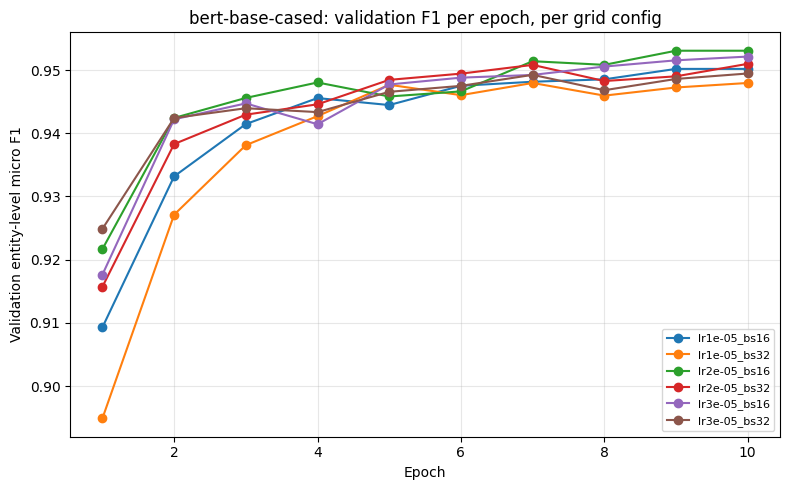

Saved /content/drive/MyDrive/IT469-NER-Project/results/annotator/bert-base-cased/learning_curves.png


In [52]:
# Plot validation F1 per epoch for every finished config, on one figure.
plt.figure(figsize=(8, 5))
for history_csv in sorted(CONFIGS_DIR.glob("*_history.csv")):
    config_name = history_csv.name[: -len("_history.csv")]
    history_df = pd.read_csv(history_csv)
    if "eval_f1" in history_df.columns:
        plt.plot(history_df["epoch"], history_df["eval_f1"], marker="o", label=config_name)

plt.xlabel("Epoch")
plt.ylabel("Validation entity-level micro F1")
plt.title(f"{CANDIDATE}: validation F1 per epoch, per grid config")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
LEARNING_CURVES_PNG.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(LEARNING_CURVES_PNG, dpi=150)
plt.show()
print(f"Saved {LEARNING_CURVES_PNG}")


## 9. Test evaluation (once)

Only runs once all 6 grid configs are finished and `test.json` does not already exist. Loads `best/`, tokenizes the test split for the first time, and evaluates exactly once.


In [53]:
if SMOKE_TEST:
    print("Skipped: SMOKE_TEST is True. Test evaluation only runs on the full 6-config grid (Section 5 of the spec).")
else:
    expected_configs = {f"lr{lr:.0e}_bs{bs}" for lr in LEARNING_RATES for bs in BATCH_SIZES}
    done_configs = {f.stem for f in CONFIGS_DIR.glob("*.json")}
    missing_configs = sorted(expected_configs - done_configs)

    if missing_configs:
        print(f"Skipped: {len(missing_configs)} grid config(s) not finished yet: {missing_configs}")
    elif TEST_JSON.exists():
        print(f"Skipped: {TEST_JSON} already exists -- test evaluation runs exactly once per candidate.")
    else:
        best_config = load_json(BEST_CONFIG_JSON)
        logger.info(
            f"All {len(expected_configs)} configs done. Evaluating best config "
            f"'{best_config['config']}' on TEST (this runs exactly once)."
        )

        test_model = AutoModelForTokenClassification.from_pretrained(BEST_DIR)
        test_tokenized = test_raw.map(tokenize_and_align_labels, batched=True, remove_columns=test_raw.column_names)

        test_args = TrainingArguments(
            output_dir=str(RESULTS_DIR / "_test_tmp"),
            per_device_eval_batch_size=32,
            fp16=True,
            report_to="none",
        )
        test_trainer = Trainer(
            model=test_model,
            args=test_args,
            data_collator=data_collator,
            processing_class=tokenizer,
            compute_metrics=compute_metrics,
        )

        test_metrics = test_trainer.evaluate(test_tokenized)
        test_report, test_records = predict_with_report(test_trainer, test_tokenized, test_raw)
        write_jsonl(test_records, TEST_PREDICTIONS_JSONL)

        test_result = {
            "candidate": CANDIDATE,
            "model_id": MODEL_ID,
            "best_config": best_config["config"],
            "test_precision": test_metrics["eval_precision"],
            "test_recall": test_metrics["eval_recall"],
            "test_f1": test_metrics["eval_f1"],
            "test_report": test_report,
            "evaluated_at": datetime.now(timezone.utc).isoformat(),
        }
        save_json(test_result, TEST_JSON)
        shutil.rmtree(RESULTS_DIR / "_test_tmp", ignore_errors=True)
        del test_trainer, test_model
        gc.collect()
        torch.cuda.empty_cache()

        logger.info(f"TEST evaluation done. test_f1={test_metrics['eval_f1']:.4f}")
        print(f"test_f1={test_metrics['eval_f1']:.4f}")
        print("Reminder: test scores are reported for completeness only and must NOT be used for any selection decision.")


2026-10-15 10:39:34,718 [INFO] All 6 configs done. Evaluating best config 'lr2e-05_bs16' on TEST (this runs exactly once).
INFO:annotator_bert-base-cased_full:All 6 configs done. Evaluating best config 'lr2e-05_bs16' on TEST (this runs exactly once).


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

Training Loss,Validation Loss,Step,Precision,Recall,F1,Accuracy
No log,0.149732,0,0.910091,0.922982,0.916491,0.983396


2026-10-15 10:39:48,230 [INFO] TEST evaluation done. test_f1=0.9165
INFO:annotator_bert-base-cased_full:TEST evaluation done. test_f1=0.9165


test_f1=0.9165
Reminder: test scores are reported for completeness only and must NOT be used for any selection decision.


## 10. Candidate comparison and selection

Reads every candidate's `best_config.json` and `test.json` from the shared Drive folder (written by each teammate's own run of this notebook) and selects the annotator by **validation** F1.


In [54]:
if SMOKE_TEST:
    print("Skipped: SMOKE_TEST is True. Candidate comparison only runs on real results.")
else:
    ALL_CANDIDATES = list(CANDIDATE_TO_MODEL_ID.keys())
    comparison_rows = []
    complete_tags = []

    for tag in ALL_CANDIDATES:
        tag_results_dir = ROOT / "results" / "annotator" / tag
        best_cfg_path = tag_results_dir / "best_config.json"
        test_path = tag_results_dir / "test.json"
        if best_cfg_path.exists() and test_path.exists():
            best_cfg = load_json(best_cfg_path)
            test_res = load_json(test_path)
            config_detail_path = tag_results_dir / "configs" / f"{best_cfg['config']}.json"
            config_detail = load_json(config_detail_path) if config_detail_path.exists() else {}
            comparison_rows.append({
                "candidate": tag,
                "model_id": CANDIDATE_TO_MODEL_ID[tag],
                "best_config": best_cfg["config"],
                "best_epoch": config_detail.get("best_epoch"),
                "val_f1": best_cfg["val_f1"],
                "test_f1": test_res["test_f1"],
            })
            complete_tags.append(tag)
        else:
            comparison_rows.append({
                "candidate": tag, "model_id": CANDIDATE_TO_MODEL_ID[tag],
                "best_config": None, "best_epoch": None, "val_f1": None, "test_f1": None,
            })

    comparison_df = pd.DataFrame(comparison_rows)
    display(comparison_df)

    missing_tags = [t for t in ALL_CANDIDATES if t not in complete_tags]
    if missing_tags:
        print(f"Not all candidates are complete yet (missing: {missing_tags}). selected_annotator.json was NOT written.")
    else:
        best_row = comparison_df.loc[comparison_df["val_f1"].idxmax()]
        selection = {
            "selected_candidate": best_row["candidate"],
            "model_id": best_row["model_id"],
            "best_model_path": str(ROOT / "checkpoints" / "annotator" / best_row["candidate"] / "best"),
            "val_f1": best_row["val_f1"],
            "test_f1": best_row["test_f1"],
            "selection_rule": (
                "Candidate with the highest CoNLL-2003 VALIDATION micro F1 among the three candidates' "
                "best grid configs. Test scores are reported for completeness only and were never used "
                "for this decision."
            ),
            "selected_at": datetime.now(timezone.utc).isoformat(),
        }
        save_json(selection, SELECTED_ANNOTATOR_JSON)
        print(f"Selected annotator: {best_row['candidate']} (val F1={best_row['val_f1']:.4f}, test F1={best_row['test_f1']:.4f})")


,candidate,model_id,best_config,best_epoch,val_f1,test_f1
0,bert-base-cased,google-bert/bert-base-cased,lr2e-05_bs16,9.0,0.953052,0.916491
1,roberta-base,FacebookAI/roberta-base,None,NaN,NaN,NaN
2,roberta-large,FacebookAI/roberta-large,None,NaN,NaN,NaN


Not all candidates are complete yet (missing: ['roberta-base', 'roberta-large']). selected_annotator.json was NOT written.


## 11. Storage check

Confirm temporary training checkpoints were actually deleted, and see how much Drive space this candidate's results are using.


In [55]:
def folder_size_mb(path):
    if not path.exists():
        return 0.0
    return sum(f.stat().st_size for f in path.rglob("*") if f.is_file()) / (1024 ** 2)


for sub in ["runs", "best", "best_tmp"]:
    sub_path = CKPT_DIR / sub
    note = "  <- should be ~0 once all grid configs are finished" if sub == "runs" else ""
    print(f"{sub_path}: {folder_size_mb(sub_path):.1f} MB{note}")

print(f"{RESULTS_DIR}: {folder_size_mb(RESULTS_DIR):.1f} MB")


/content/drive/MyDrive/IT469-NER-Project/checkpoints/annotator/bert-base-cased/runs: 0.0 MB  <- should be ~0 once all grid configs are finished
/content/drive/MyDrive/IT469-NER-Project/checkpoints/annotator/bert-base-cased/best: 411.6 MB
/content/drive/MyDrive/IT469-NER-Project/checkpoints/annotator/bert-base-cased/best_tmp: 0.0 MB
/content/drive/MyDrive/IT469-NER-Project/results/annotator/bert-base-cased: 2.2 MB


## 12. References

[1] J. Devlin, M.-W. Chang, K. Lee, and K. Toutanova, "BERT: Pre-training of deep bidirectional
transformers for language understanding," in *Proc. NAACL-HLT*, 2019, pp. 4171-4186.
doi:10.18653/v1/N19-1423

[2] Y. Liu et al., "RoBERTa: A robustly optimized BERT pretraining approach," arXiv:1907.11692, 2019.

[3] E. F. Tjong Kim Sang and F. De Meulder, "Introduction to the CoNLL-2003 shared task:
Language-independent named entity recognition," in *Proc. CoNLL*, 2003, pp. 142-147.
arXiv:cs/0306050

[4] Z. Wang, J. Shang, L. Liu, L. Lu, J. Liu, and J. Han, "CrossWeigh: Training named entity tagger
from imperfect annotations," in *Proc. EMNLP-IJCNLP*, 2019. https://aclanthology.org/D19-1519/

[5] I. Loshchilov and F. Hutter, "Decoupled weight decay regularization," in *Proc. ICLR*, 2019.
arXiv:1711.05101

[6] P. Micikevicius et al., "Mixed precision training," in *Proc. ICLR*, 2018. arXiv:1710.03740

[7] T. Wolf et al., "Transformers: State-of-the-art natural language processing," in *Proc. EMNLP:
System Demonstrations*, 2020, pp. 38-45. doi:10.18653/v1/2020.emnlp-demos.6

[8] Q. Lhoest et al., "Datasets: A community library for natural language processing," in *Proc.
EMNLP: System Demonstrations*, 2021. doi:10.18653/v1/2021.emnlp-demo.21

[9] H. Nakayama, "seqeval: A Python framework for sequence labeling evaluation," 2018.
https://github.com/chakki-works/seqeval

**Resource links**

- CoNLL-2003 on Hugging Face: https://huggingface.co/datasets/eriktks/conll2003
- Official CoNLL-2003 shared-task page: https://www.clips.uantwerpen.be/conll2003/ner/
- `google-bert/bert-base-cased`: https://huggingface.co/google-bert/bert-base-cased
- `FacebookAI/roberta-base`: https://huggingface.co/FacebookAI/roberta-base
- `FacebookAI/roberta-large`: https://huggingface.co/FacebookAI/roberta-large
